# Bank marketing, part 2: who should the call centre phone first?

**Business question.** The call centre can only phone a fraction of the client list.
Who should be called first, and how much better is that than calling at random?

**Approach.** Build a *lead score*: a number for each client, known **before** the call, that ranks clients
from most to least likely to subscribe. Then measure how many subscribers the call centre reaches if it works
down that ranking instead of calling in random order.

**What this notebook is careful about**

1. **No leakage.** Only information available before dialling is used. Call duration is excluded (section 3).
2. **Testing on the future.** The model is trained on earlier calls and tested on later ones, because that is how
   it would be used (section 5).
3. **Honest metrics.** Only 11% of contacts subscribe, so accuracy is meaningless here. The headline figures are
   lift and cumulative gains (section 6).
4. **Simple first.** A logistic regression that can be explained line by line is compared with a more flexible
   tree-based model; the more complex model has to earn its place.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42     # one fixed random seed, so every run gives the same numbers

DATA_DIR = Path("..") / "data"
IMG_DIR = Path("..") / "images"
IMG_DIR.mkdir(exist_ok=True)

pd.set_option("display.width", 140)

In [2]:
# Same chart settings as notebook 01
NAVY, ORANGE, GREY = "#1f3a5f", "#d9822b", "#9aa5b1"

plt.rcParams.update({
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e5e8eb",
})

## 2. Load and prepare the data

Same rules as notebook 01:

- drop the 12 exact duplicate rows,
- keep `"unknown"` as its own category (a client who did not state their education may behave differently, and
  guessing a value would invent data),
- `pdays` uses the number 999 to mean "never contacted before". Feeding 999 to a model as if it were a number of
  days would be wrong, so it becomes a yes/no column `contacted_before`.

In [3]:
raw = pd.read_csv(DATA_DIR / "bank-additional-full.csv", sep=";")
df = raw.drop_duplicates().reset_index(drop=True)     # rows stay in date order

df["subscribed"] = (df["y"] == "yes").astype(int)
df["contacted_before"] = np.where(df["pdays"] == 999, "no", "yes")

print("Rows:", len(df))
print("Subscribers:", df["subscribed"].sum())
print(f"Conversion rate: {df['subscribed'].mean():.2%}")
print()
print(df["contacted_before"].value_counts())

Rows: 41176
Subscribers: 4639
Conversion rate: 11.27%

contacted_before
no     39661
yes     1515
Name: count, dtype: int64


The year is not in the file, but the rows are in date order, so it can be recovered: a new year starts whenever
the month number goes down from one row to the next (explained in notebook 01). It is used for describing
periods only, never as a model feature.

In [4]:
month_number = df["month"].map({"jan": 1, "feb": 2, "mar": 3, "apr": 4, "may": 5, "jun": 6,
                                "jul": 7, "aug": 8, "sep": 9, "oct": 10, "nov": 11, "dec": 12})
df["year"] = 2008 + (month_number.diff() < 0).cumsum()
df["period"] = df["month"].str.capitalize() + " " + df["year"].astype(str)   # e.g. "May 2008"

df.groupby("year")["subscribed"].agg(contacts="size", conversion_rate="mean").round(3)

,contacts,conversion_rate
year,,
2008,27682,0.048
2009,11436,0.195
2010,2058,0.521


## 3. Choosing features: what is known before the call?

A lead score is only useful if every input is available **before** the phone is picked up.
Each column was checked against that rule.

| Column(s) | Used? | Why |
|---|---|---|
| `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` | Yes | Client profile, known in advance |
| `contact` (mobile or landline) | Yes | The bank knows which number it holds |
| `previous`, `poutcome`, `contacted_before` | Yes | History from earlier campaigns |
| `campaign` (calls so far in this campaign) | Yes, with a caveat | Known before dialling, see note below |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Tested both ways | Known in advance, but they describe *when* the call was made, not *who* was called (section 7) |
| `month`, `day_of_week` | No | Calendar features. With only 2.5 years of data, "month" cannot be separated from one-off events: some months appear almost only in the unusual final period |
| `pdays` | Replaced | By `contacted_before` |
| **`duration`** | **Never** | **Leakage, see below** |

### The leakage trap: `duration`

`duration` is the length of the call in seconds. It predicts the outcome extremely well: long calls are the ones
where the client is signing up, and a call of 0 seconds is always a "no". But the length of a call is only known
**after** the call, when the outcome is known too. A model that uses it cannot be used to decide whom to call.
The dataset authors say so explicitly in their notes. Models that include it report impressive scores that would
never be achieved in practice; section 8 shows how large the illusion is.

### Caveat on `campaign`

Each row stores the final number of calls made to the client. Clients who say yes are not called again, so low
counts are slightly favoured by construction. The column is kept because the number of calls already made is
real information the call centre has, but its effect should be read with that in mind.

In [5]:
client_features = ["age", "job", "marital", "education", "default", "housing", "loan"]
history_features = ["contact", "campaign", "previous", "poutcome", "contacted_before"]
economy_features = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

# Two feature sets to compare
WHO = client_features + history_features          # who is being called
WHO_AND_WHEN = WHO + economy_features             # ... plus the economic climate on the day

target = df["subscribed"]

## 4. Conversion changed enormously over time

Before splitting the data, look at how the conversion rate moved. The rows are in date order, so cutting them
into 20 equal blocks gives a timeline.

In [6]:
df["time_block"] = pd.cut(df.index, bins=20, labels=False)     # 20 equal slices in date order

timeline = df.groupby("time_block").agg(
    conversion_rate=("subscribed", "mean"),
    euribor=("euribor3m", "mean"),
    starts=("period", "first"),
)
timeline.round(3)

,conversion_rate,euribor,starts
time_block,,,
0,0.021,4.856,May 2008
1,0.034,4.858,May 2008
2,0.034,4.857,May 2008
3,0.037,4.861,May 2008
4,0.044,4.922,Jun 2008
5,0.040,4.959,Jun 2008
6,0.059,4.962,Jul 2008
7,0.074,4.959,Jul 2008
8,0.059,4.963,Jul 2008


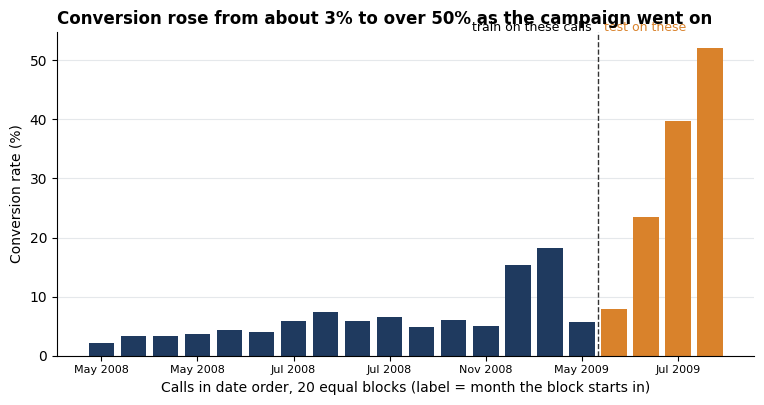

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(timeline.index, timeline["conversion_rate"] * 100, color=[NAVY] * 16 + [ORANGE] * 4)
ax.axvline(15.5, color="#333333", linestyle="--", linewidth=1)
ax.text(15.3, 55, "train on these calls", ha="right", fontsize=9)
ax.text(15.7, 55, "test on these", ha="left", fontsize=9, color=ORANGE)
ax.set_xticks(timeline.index[::3])
ax.set_xticklabels(timeline["starts"].iloc[::3], rotation=0, fontsize=8)
ax.set_xlabel("Calls in date order, 20 equal blocks (label = month the block starts in)")
ax.set_ylabel("Conversion rate (%)")
ax.set_title("Conversion rose from about 3% to over 50% as the campaign went on")
ax.grid(axis="x", visible=False)
fig.savefig(IMG_DIR / "05_conversion_over_time.png")
plt.show()

**What the timeline shows.** Conversion was about 2% to 7% for the first 12 blocks (May to Aug 2008), then
rose in steps: 15% to 18% in blocks 13 and 14, 24% in block 17, 40% in block 18 and 52% in the last block. The
Euribor interest rate fell over the same stretch, from about 4.9 to about 0.8. The later calls are simply a different
population: fewer, more selected clients, and a bank that had changed how it worked during the financial crisis.
This is the central difficulty for any model built on this file: **the future does not look like the past.**
The chart marks where the 80/20 split in the next section falls.

## 5. Splitting the data: train on the past, test on the future

Two ways of testing are used side by side.

- **Time-ordered split (the headline).** Train on the first 80% of calls, test on the last 20%.
  This copies real use: a model built from past campaigns scores clients in a later one.
- **Random 5-fold cross-validation (for comparison).** The rows are shuffled, so every training set contains
  calls from the same weeks as the test set. This is the usual textbook method, and for this dataset it is too
  optimistic: the model gets to "peek" at the period it is tested on.

In [8]:
split_at = int(len(df) * 0.8)

train = df.iloc[:split_at]
test = df.iloc[split_at:]

for name, part in [("Train", train), ("Test", test)]:
    print(f"{name}: {len(part):>6,} calls, {part['period'].iloc[0]} to {part['period'].iloc[-1]}, "
          f"conversion {part['subscribed'].mean():.1%}")

Train: 32,940 calls, May 2008 to May 2009, conversion 6.4%
Test:  8,236 calls, May 2009 to Nov 2010, conversion 30.8%


The cut sits in May 2009. The training period has a 6.4% conversion rate and the test period 30.8%, nearly five
times higher. A model tested on the later period is therefore tested under hard, realistic conditions: it must rank
clients in a market that behaves differently from the one it learned from. Because the base rates differ so much,
**ROC AUC, the share reached and lift are compared between models; "average precision" is not compared between the
two ways of testing** (its baseline is the conversion rate, which differs).

## 6. Models and metrics

### Two models

- **Logistic regression**: the explainable baseline. Each feature gets one weight, which can be read as an odds ratio.
- **Gradient boosting** (`HistGradientBoostingClassifier`): many small decision trees built one after another.
  It can pick up curves and interactions that logistic regression misses, at the cost of being harder to explain.

Both sit in an sklearn `Pipeline`, so the preprocessing is learned from the training rows only and then applied
to the test rows. That prevents a quieter kind of leakage (for example, scaling with averages that include the test data).

- text columns are **one-hot encoded** (one 0/1 column per category; `"unknown"` simply becomes one more category),
- number columns are **standardised** (mean 0, standard deviation 1), which logistic regression needs so that
  its weights are comparable.

In [9]:
def category_name(column, category):
    # Readable names for the one-hot columns, e.g. "job = student"
    return f"{column} = {category}"


def make_pipeline(model_name, features):
    # Preprocessing + model in one object. `features` is the list of columns to use.
    text_cols = [c for c in features if df[c].dtype == object]
    number_cols = [c for c in features if c not in text_cols]

    preprocess = ColumnTransformer([
        # handle_unknown="ignore": a category never seen in training becomes all zeros instead of an error
        ("text", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                               feature_name_combiner=category_name), text_cols),
        ("numbers", StandardScaler(), number_cols),
    ])

    if model_name == "Logistic regression":
        model = LogisticRegression(max_iter=2000)
    else:
        # Small, shallow trees keep the model fast and limit over-fitting
        model = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED)

    return Pipeline([("preprocess", preprocess), ("model", model)])

### Why not accuracy?

Only about one contact in nine subscribes. A "model" that predicts *no* for everybody is right almost nine times
in ten, and is useless.

In [10]:
print(f"Accuracy of predicting 'no' for every client: {1 - target.mean():.1%}")

Accuracy of predicting 'no' for every client: 88.7%


The class imbalance is handled through the choice of metrics rather than by re-sampling the data. The call
centre does not need a yes/no label; it needs a **ranking**. The metrics below all judge the ranking:

- **ROC AUC**: the chance that a randomly chosen subscriber gets a higher score than a randomly chosen
  non-subscriber. 0.5 is a coin flip, 1.0 is perfect.
- **Average precision** (area under the precision-recall curve): focuses on the rare "yes" class. Its baseline
  is the conversion rate itself, so it can only be compared between tests with the same conversion rate.
- **Share of subscribers reached in the top 20%**: sort clients by score, call the top fifth, count how many of
  all subscribers were in that fifth. Random calling reaches 20%.
- **Lift** = that share divided by 20%. A lift of 2 means twice as many subscribers as random calling for the
  same number of calls.

In [11]:
def share_reached(y_true, scores, top_share=0.2):
    # Share of all subscribers found among the `top_share` highest-scored clients.
    order = np.argsort(-np.asarray(scores), kind="stable")     # positions from highest to lowest score
    n_called = int(round(top_share * len(order)))
    return np.asarray(y_true)[order][:n_called].sum() / np.sum(y_true)


def evaluate(y_true, scores):
    # The four ranking metrics used throughout this notebook.
    reached = share_reached(y_true, scores)
    return {
        "ROC AUC": roc_auc_score(y_true, scores),
        "Avg precision": average_precision_score(y_true, scores),
        "Reached in top 20%": reached,
        "Lift at 20%": reached / 0.2,
    }

## 7. Results: two models, two feature sets, two ways of testing

The loop below fits every combination. For the time split, the pipeline is trained on `train` and scores `test`.
For the random split, `cross_val_predict` gives every row a score from a model that did not see that row.

In [12]:
random_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

results = []
test_scores = {}        # keep the test-set scores for the charts later

for features_name, features in [("Who", WHO), ("Who + economy", WHO_AND_WHEN)]:
    for model_name in ["Logistic regression", "Gradient boosting"]:

        # (a) time-ordered split
        pipeline = make_pipeline(model_name, features)
        pipeline.fit(train[features], train["subscribed"])
        scores = pipeline.predict_proba(test[features])[:, 1]       # column 1 = probability of "yes"
        test_scores[(features_name, model_name)] = scores
        results.append({"Features": features_name, "Model": model_name, "Validation": "Time split",
                        **evaluate(test["subscribed"], scores)})

        # (b) random 5-fold cross-validation on all rows
        cv_scores = cross_val_predict(make_pipeline(model_name, features), df[features], target,
                                      cv=random_folds, method="predict_proba")[:, 1]
        results.append({"Features": features_name, "Model": model_name, "Validation": "Random 5-fold",
                        **evaluate(target, cv_scores)})

results = pd.DataFrame(results)
results.set_index(["Validation", "Features", "Model"]).sort_index(ascending=[False, True, False]).round(3)

ROC AUC  Avg precision  Reached in top 20%  Lift at 20%
Validation    Features      Model                                                                       
Time split    Who           Logistic regression    0.702          0.543               0.395        1.973
                            Gradient boosting      0.697          0.511               0.380        1.900
              Who + economy Logistic regression    0.629          0.478               0.377        1.885
                            Gradient boosting      0.655          0.465               0.336        1.678
Random 5-fold Who           Logistic regression    0.731          0.354               0.472        2.362
                            Gradient boosting      0.738          0.367               0.490        2.451
              Who + economy Logistic regression    0.782          0.437               0.609        3.043
                            Gradient boosting      0.799          0.459               0.640        3.200

In [13]:
# ROC AUC side by side: random split against time split
auc_table = results.pivot(index=["Features", "Model"], columns="Validation", values="ROC AUC")
auc_table = auc_table[["Random 5-fold", "Time split"]]
auc_table["Drop"] = auc_table["Random 5-fold"] - auc_table["Time split"]
auc_table.round(3)

Validation                         Random 5-fold  Time split   Drop
Features      Model                                                
Who           Gradient boosting            0.738       0.697  0.040
              Logistic regression          0.731       0.702  0.029
Who + economy Gradient boosting            0.799       0.655  0.143
              Logistic regression          0.782       0.629  0.152

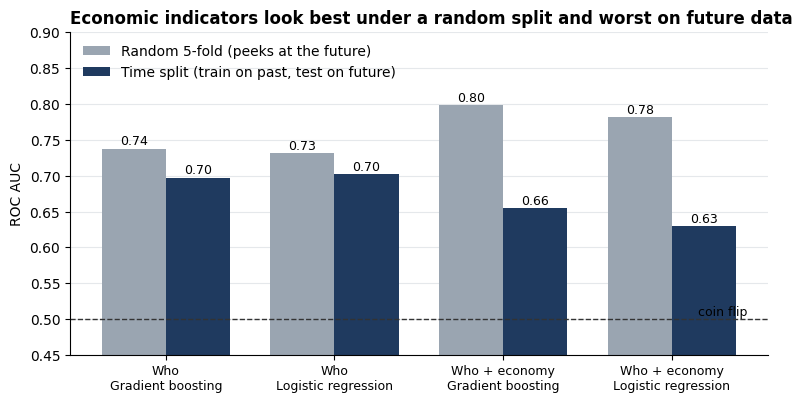

In [14]:
fig, ax = plt.subplots(figsize=(9, 4.2))
labels = [f"{features}\n{model}" for features, model in auc_table.index]
x = np.arange(len(labels))
ax.bar(x - 0.19, auc_table["Random 5-fold"], width=0.38, color=GREY, label="Random 5-fold (peeks at the future)")
ax.bar(x + 0.19, auc_table["Time split"], width=0.38, color=NAVY, label="Time split (train on past, test on future)")
for i, (a, b) in enumerate(zip(auc_table["Random 5-fold"], auc_table["Time split"])):
    ax.text(i - 0.19, a + 0.005, f"{a:.2f}", ha="center", fontsize=9)
    ax.text(i + 0.19, b + 0.005, f"{b:.2f}", ha="center", fontsize=9)
ax.axhline(0.5, color="#333333", linestyle="--", linewidth=1)
ax.text(3.45, 0.505, "coin flip", ha="right", fontsize=9)
ax.set_ylim(0.45, 0.9)
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=9)
ax.set_ylabel("ROC AUC")
ax.set_title("Economic indicators look best under a random split and worst on future data")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper left")
fig.savefig(IMG_DIR / "06_random_vs_time_validation.png")
plt.show()

**Reading the table and chart.**

- **On the time split, the simple "who" logistic regression is the best model**: ROC AUC 0.70, and 39.5% of
  subscribers reached by calling the top 20% (lift 1.97). Gradient boosting does not beat it (AUC 0.70, 38.0% reached),
  so the simpler, explainable model is chosen.
- **A random split looks better than the truth.** For the same "who" logistic regression, random 5-fold gives a lift
  of 2.36 against 1.97 on the time split. For "who" features the AUC drop is modest (0.73 to 0.70), so the model
  is not badly hurt by the change of period, but it is clearly less impressive on future calls.
- **Adding the economic indicators is where the random split misleads most.** With them, a random split gives AUC
  0.78 to 0.80 and a lift of 3.0 to 3.2. On future calls the same models fall to AUC 0.63 to 0.66 and a lift of 1.7 to 1.9,
  worse than the model without them. The indicators describe *when* a call happened. A random split lets the model
  learn "calls made at this Euribor level were successful" from other calls made in the same weeks, which does not
  carry over to a new period. For that reason the economic indicators are left out of the lead score.
- Absolute performance is moderate. An AUC of 0.70 means the score is useful for ordering clients, not that it
  predicts individual clients reliably.

### Is the time-split result a fluke of one cut-off date?

One split is one experiment. As a check, the same comparison is repeated with a rolling scheme
(`TimeSeriesSplit`): the data is cut into six consecutive blocks; train on block 1 and test on block 2, then
train on blocks 1-2 and test on block 3, and so on. Every test block lies in the future of its training data.

In [15]:
rolling = []
for fold, (train_idx, test_idx) in enumerate(TimeSeriesSplit(n_splits=5).split(df), start=1):
    past, future = df.iloc[train_idx], df.iloc[test_idx]
    row = {"Fold": fold,
           "Test period": f"{future['period'].iloc[0]} to {future['period'].iloc[-1]}",
           "Test conversion": future["subscribed"].mean()}
    for features_name, features in [("Who", WHO), ("Who + economy", WHO_AND_WHEN)]:
        pipeline = make_pipeline("Logistic regression", features).fit(past[features], past["subscribed"])
        row[f"AUC: {features_name}"] = roc_auc_score(future["subscribed"], pipeline.predict_proba(future[features])[:, 1])
    rolling.append(row)

pd.DataFrame(rolling).set_index("Fold").round(3)

,Test period,Test conversion,AUC: Who,AUC: Who + economy
Fold,,,,
1,May 2008 to Jul 2008,0.046,0.553,0.528
2,Jul 2008 to Aug 2008,0.065,0.528,0.522
3,Aug 2008 to Nov 2008,0.053,0.437,0.410
4,Nov 2008 to May 2009,0.127,0.617,0.657
5,May 2009 to Nov 2010,0.355,0.684,0.635


**Reading the result.** The picture is less comfortable than the single split. In the first four folds the
"who" model has AUC between 0.44 and 0.62, close to a coin flip (fold 3 is below 0.5), partly because early folds
are trained on very little data and because conversion in those weeks was only 5% to 13%. Only in the last fold,
which matches the headline split, is the AUC 0.68. The economic indicators lower the AUC in four of the five folds
(they help only in fold 4). Two lessons: the 0.70 headline is **specific to the later period**, where a previous success
becomes common, and a model trained on a few early weeks would not have been much use. Any real deployment needs
regular re-training and re-testing.

## 8. For illustration only: how good the model *looks* if `duration` is included

This cell exists to show the size of the leakage trap described in section 3. **This model is not used anywhere
else and could never be used in practice**, because call duration does not exist until the call is over.

In [16]:
LEAKY = WHO_AND_WHEN + ["duration"]      # do NOT do this in a real lead-scoring model

leaky_scores = cross_val_predict(make_pipeline("Gradient boosting", LEAKY), df[LEAKY], target,
                                 cv=random_folds, method="predict_proba")[:, 1]

honest = results[(results["Features"] == "Who") & (results["Model"] == "Logistic regression")
                 & (results["Validation"] == "Time split")].iloc[0]

pd.DataFrame({
    "Leaky: with duration, random split": evaluate(target, leaky_scores),
    "Honest: no duration, no economy, time split": honest[["ROC AUC", "Avg precision", "Reached in top 20%", "Lift at 20%"]],
}).T.astype(float).round(3)

,ROC AUC,Avg precision,Reached in top 20%,Lift at 20%
"Leaky: with duration, random split",0.947,0.659,0.875,4.373
"Honest: no duration, no economy, time split",0.702,0.543,0.395,1.973


**Reading the result.** With `duration` included and a random split, the model appears to reach 87.5% of
subscribers in the top 20% (lift 4.4, ROC AUC 0.95). The honest model reaches 39.5% (lift 2.0, AUC 0.70). The
gap of more than 45 percentage points is not skill: it is the information leaking in from the end of the call.
Published results on this dataset that report AUC near 0.9 almost always include `duration`. This is the reason the
column is excluded everywhere else.

## 9. The chosen model and what it means for the call centre

The lead score used from here on is the **logistic regression on the "who" features**, trained on the first 80%
of calls. All figures below are measured on the last 20%, which the model never saw.

### Cumulative gains

Sort the test clients from highest to lowest score and work down the list. The gains curve shows what share of
all subscribers has been reached after calling the top 10%, 20%, 30%... of the list.

In [17]:
def gains_curve(y_true, scores):
    # x = share of clients called (best scores first), y = share of all subscribers reached so far.
    order = np.argsort(-np.asarray(scores), kind="stable")
    found = np.cumsum(np.asarray(y_true)[order])
    share_called = np.arange(1, len(order) + 1) / len(order)
    return share_called, found / found[-1]

final_scores = test_scores[("Who", "Logistic regression")]
y_test = test["subscribed"].to_numpy()

x_model, y_model = gains_curve(y_test, final_scores)
x_best, y_best = gains_curve(y_test, y_test)        # a perfect ranking: all subscribers first

# A one-line business rule to beat: call clients with a previous success first, everyone else in random order
rng = np.random.default_rng(SEED)
rule_scores = (test["poutcome"] == "success").to_numpy() + rng.random(len(test)) * 0.5   # random tie-break
x_rule, y_rule = gains_curve(y_test, rule_scores)

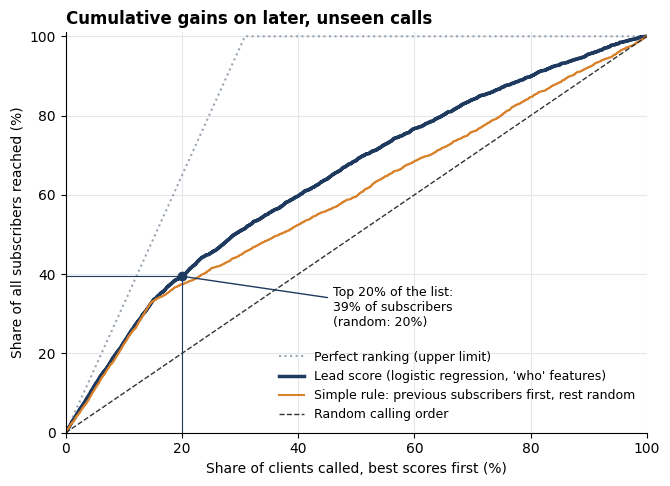

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.plot(x_best * 100, y_best * 100, color=GREY, linestyle=":", linewidth=1.5, label="Perfect ranking (upper limit)")
ax.plot(x_model * 100, y_model * 100, color=NAVY, linewidth=2.5, label="Lead score (logistic regression, 'who' features)")
ax.plot(x_rule * 100, y_rule * 100, color=ORANGE, linewidth=1.5, label="Simple rule: previous subscribers first, rest random")
ax.plot([0, 100], [0, 100], color="#333333", linestyle="--", linewidth=1, label="Random calling order")

# Mark the "top 20%" reading on the chart
reached_20 = share_reached(y_test, final_scores, 0.2) * 100
ax.plot([20, 20], [0, reached_20], color=NAVY, linewidth=0.8)
ax.plot([0, 20], [reached_20, reached_20], color=NAVY, linewidth=0.8)
ax.plot(20, reached_20, "o", color=NAVY)
ax.annotate(f"Top 20% of the list:\n{reached_20:.0f}% of subscribers\n(random: 20%)", xy=(20, reached_20),
            xytext=(46, 27), fontsize=9, arrowprops={"arrowstyle": "-", "color": NAVY})

ax.set_xlim(0, 100)
ax.set_ylim(0, 101)
ax.set_xlabel("Share of clients called, best scores first (%)")
ax.set_ylabel("Share of all subscribers reached (%)")
ax.set_title("Cumulative gains on later, unseen calls")
ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.savefig(IMG_DIR / "07_cumulative_gains.png")
plt.show()

The model against the simple rule and against random calling, at several cut-offs:

In [19]:
comparison = pd.DataFrame({
    "Lead score": [share_reached(y_test, final_scores, share) for share in [0.1, 0.2, 0.3, 0.5]],
    "Simple rule": [share_reached(y_test, rule_scores, share) for share in [0.1, 0.2, 0.3, 0.5]],
    "Random calling": [0.1, 0.2, 0.3, 0.5],
}, index=["Top 10%", "Top 20%", "Top 30%", "Top 50%"])
comparison["Lift of lead score"] = comparison["Lead score"] / comparison["Random calling"]
comparison.round(3)

,Lead score,Simple rule,Random calling,Lift of lead score
Top 10%,0.228,0.223,0.1,2.276
Top 20%,0.395,0.374,0.2,1.973
Top 30%,0.509,0.448,0.3,1.696
Top 50%,0.688,0.596,0.5,1.375


### Decile lift table

The same information as a table. Test clients are sorted by score and cut into ten equal groups ("deciles");
decile 1 holds the 10% of clients with the highest scores.

In [20]:
scored = pd.DataFrame({"score": final_scores, "subscribed": y_test})
scored = scored.sort_values("score", ascending=False, kind="stable").reset_index(drop=True)
scored["decile"] = scored.index * 10 // len(scored) + 1        # 1 = best-scored tenth

deciles = scored.groupby("decile")["subscribed"].agg(clients="size", subscribers="sum")
deciles["conversion_rate"] = deciles["subscribers"] / deciles["clients"]
deciles["lift"] = deciles["conversion_rate"] / scored["subscribed"].mean()        # vs the test-set average
deciles["cum_share_of_subscribers"] = deciles["subscribers"].cumsum() / deciles["subscribers"].sum()
deciles["cum_lift"] = deciles["cum_share_of_subscribers"] / (deciles["clients"].cumsum() / len(scored))

print(f"Test-set average conversion: {scored['subscribed'].mean():.1%}")
deciles.round(3)

Test-set average conversion: 30.8%


,clients,subscribers,conversion_rate,lift,cum_share_of_subscribers,cum_lift
decile,,,,,,
1,824,578,0.701,2.275,0.228,2.275
2,824,424,0.515,1.669,0.395,1.972
3,823,290,0.352,1.143,0.509,1.696
4,824,224,0.272,0.882,0.597,1.492
5,823,230,0.279,0.907,0.688,1.375
6,824,202,0.245,0.795,0.767,1.279
7,824,186,0.226,0.732,0.840,1.201
8,823,148,0.180,0.583,0.899,1.123
9,824,143,0.174,0.563,0.955,1.061


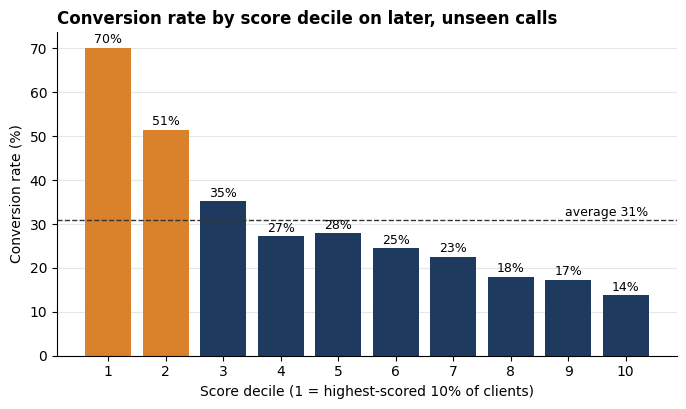

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(deciles.index, deciles["conversion_rate"] * 100, color=[ORANGE] * 2 + [NAVY] * 8)
average = scored["subscribed"].mean() * 100
ax.axhline(average, color="#333333", linestyle="--", linewidth=1)
ax.text(10.4, average + 1, f"average {average:.0f}%", ha="right", fontsize=9)
for decile, rate in zip(deciles.index, deciles["conversion_rate"] * 100):
    ax.text(decile, rate + 1, f"{rate:.0f}%", ha="center", fontsize=9)
ax.set_xticks(deciles.index)
ax.set_xlabel("Score decile (1 = highest-scored 10% of clients)")
ax.set_ylabel("Conversion rate (%)")
ax.set_title("Conversion rate by score decile on later, unseen calls")
ax.grid(axis="x", visible=False)
fig.savefig(IMG_DIR / "08_conversion_by_score_decile.png")
plt.show()

**Reading the gains chart and tables (later, unseen calls).**

- Calling the top 10% of the scored list reaches 22.8% of subscribers (lift 2.28); the top 20% reaches 39.5% of
  subscribers (lift 1.97, about twice as many as random calling); the top 30% reaches 50.9%; the top 50% reaches 68.8%.
- The top-scored decile converts at 70.1%, against a test-set average of 30.8%. The bottom decile converts at 13.9%.
  The deciles are not perfectly ordered in the middle (decile 5 at 27.9% is slightly above decile 4 at 27.2%), which is normal noise
  for groups of about 820 clients.
- **The simple rule is a strong competitor.** "Call previous subscribers first, then everyone else in random order"
  reaches 37.4% in the top 20%, against 39.5% for the model. The model's edge over the one-line rule is small at the top
  (22.8% against 22.3% at 10%) and grows further down the list (50.9% against 44.8% at 30%; 68.8% against 59.6% at 50%).
  The honest summary is that **most of the lift comes from one fact, a previous success, and the model adds a
  modest improvement beyond it.** The next cells test this directly.

### Where does the lift come from?

Notebook 01 found that a previous success is by far the strongest signal. The next two cells check how much of
the lead score is simply that one fact: first, who is in the top decile; second, how well the score ranks
clients *within* each history group.

In [22]:
test_view = test.assign(score=final_scores)
top_decile = test_view.sort_values("score", ascending=False, kind="stable").head(len(test) // 10)

pd.DataFrame({
    "Share of top decile": top_decile["poutcome"].value_counts(normalize=True),
    "Share of all test clients": test["poutcome"].value_counts(normalize=True),
    "Share of training clients": train["poutcome"].value_counts(normalize=True),
}).fillna(0).round(3)

,Share of top decile,Share of all test clients,Share of training clients
poutcome,,,
failure,0.029,0.260,0.064
nonexistent,0.000,0.593,0.931
success,0.971,0.146,0.005


In [23]:
rows = []
for outcome, group in test_view.groupby("poutcome"):
    rows.append({"Previous campaign outcome": outcome, "Test clients": len(group),
                 "Conversion rate": group["subscribed"].mean(),
                 "ROC AUC within group": roc_auc_score(group["subscribed"], group["score"])})
pd.DataFrame(rows).set_index("Previous campaign outcome").round(3)

,Test clients,Conversion rate,ROC AUC within group
Previous campaign outcome,,,
failure,2145,0.224,0.608
nonexistent,4886,0.251,0.609
success,1205,0.690,0.551


**Reading the result.** The top decile is 97.1% previous successes. In the test period, previous successes make up
14.6% of calls, but in the training period only 0.5% did, so the model learned the "previous success" effect from a very
small group. Within each history group, the score's ROC AUC is 0.61 for previous failures, 0.61 for clients with no
previous campaign and 0.55 for previous successes. So beyond the previous-campaign result, the profile and contact
features rank clients only weakly. That is a real but modest signal, and it is what the model's edge over the simple rule rests on.

### Can the scores be read as probabilities? No, only as a ranking

The model was trained on a period with a much lower conversion rate than the test period, so the probabilities
it outputs are too low for the later period.

In [24]:
print(f"Average predicted probability on the test set: {final_scores.mean():.1%}")
print(f"Actual conversion rate on the test set:        {y_test.mean():.1%}")

Average predicted probability on the test set: 14.1%
Actual conversion rate on the test set:        30.8%


The average predicted probability is 14.1% while the actual conversion rate is 30.8%. The scores are good for
**ordering** clients but must not be quoted as "a 14% chance of subscribing". Turning scores into reliable
probabilities would require recalibrating on recent data.

## 10. Illustrative profit scenario

**The figures in this section are assumptions made for illustration. The dataset contains no cost or revenue
information.** The point is the method: once the bank plugs in its own numbers, the same few lines give the
cut-off.

Assume each call costs a fixed amount (agent time, telephony) and each subscription is worth a fixed amount to
the bank. Calling the top *k* clients then earns

`profit = value per subscription x subscribers reached - cost per call x k`

The calculation uses the **actual outcomes** of the test clients in score order, not the model's predicted
probabilities (which section 9 showed are not reliable as probabilities).

In [25]:
def profit_curve(cost_per_call, value_per_subscription):
    # Profit after calling the top 1, 2, 3, ... test clients in score order.
    calls_made = np.arange(1, len(scored) + 1)
    subscribers_reached = scored["subscribed"].cumsum().to_numpy()
    return value_per_subscription * subscribers_reached - cost_per_call * calls_made

# ASSUMED figures in EUR: (cost per call, value per subscription)
scenarios = {
    "Cost 5, value 15": (5, 15),
    "Cost 5, value 20": (5, 20),
    "Cost 5, value 30": (5, 30),
    "Cost 3, value 30": (3, 30),
}

rows = []
for name, (cost, value) in scenarios.items():
    profit = profit_curve(cost, value)
    best = profit.argmax()                              # position of the highest profit
    rows.append({
        "Scenario": name,
        "Break-even conversion rate": cost / value,
        "Best share of list to call": (best + 1) / len(scored),
        "Profit at best cut-off": profit[best],
        "Profit if everyone is called": profit[-1],
    })
profit_table = pd.DataFrame(rows).set_index("Scenario")
profit_table.round(3)

,Break-even conversion rate,Best share of list to call,Profit at best cut-off,Profit if everyone is called
Scenario,,,,
"Cost 5, value 15",0.333,0.234,7195,-3095
"Cost 5, value 20",0.250,0.504,14445,9600
"Cost 5, value 30",0.167,0.842,35850,34990
"Cost 3, value 30",0.100,0.990,51618,51462


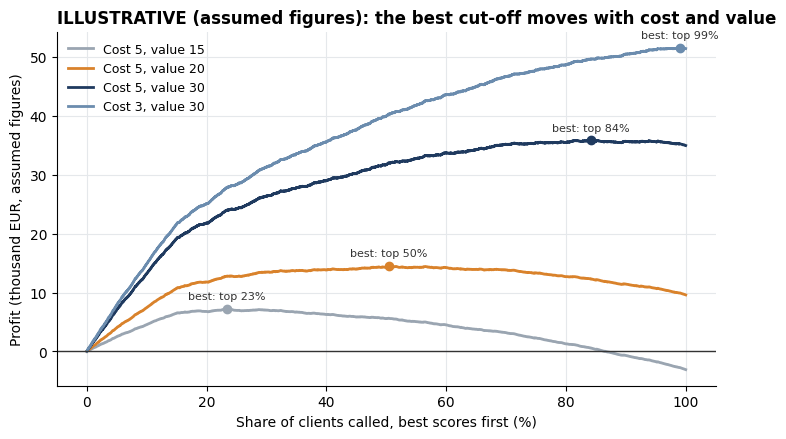

In [26]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))
share_called = np.arange(1, len(scored) + 1) / len(scored) * 100
for (name, (cost, value)), color in zip(scenarios.items(), [GREY, ORANGE, NAVY, "#6b8cae"]):
    profit = profit_curve(cost, value) / 1000
    best = profit.argmax()
    ax.plot(share_called, profit, color=color, linewidth=2, label=name)
    ax.plot(share_called[best], profit[best], "o", color=color)
    ax.annotate(f"best: top {share_called[best]:.0f}%", xy=(share_called[best], profit[best]),
                xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8, color="#333333")
ax.axhline(0, color="#333333", linewidth=1)
ax.set_xlabel("Share of clients called, best scores first (%)")
ax.set_ylabel("Profit (thousand EUR, assumed figures)")
ax.set_title("ILLUSTRATIVE (assumed figures): the best cut-off moves with cost and value")
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.savefig(IMG_DIR / "09_illustrative_profit_scenarios.png")
plt.show()

**Reading the table and chart (assumed figures).** The best share of the list to call depends entirely on the
cost and value assumed, and the break-even conversion rate (cost divided by value) tells the story:

- Cost 5, value 15: break-even is 33%. Calling everybody loses EUR 3,095; calling only the top 23.4% earns EUR 7,195.
- Cost 5, value 20: break-even is 25%. The best cut-off is the top 50.4% (EUR 14,445, against EUR 9,600 for calling everyone).
- Cost 5, value 30 and cost 3, value 30: the break-even rate is below most of the list, so almost everyone is worth
  calling (best cut-offs 84.2% and 99.0%), and ranking adds little (EUR 35,850 against 34,990, and EUR 51,618 against 51,462).

Ranking pays off when calls are expensive relative to the value of a sale, or when capacity is limited.
These conclusions are for the test period only, whose conversion rate (30.8%) was unusually high. On the
bank's own current data, with its real costs and values, the numbers would be different.

## 11. What drives the score?

### Odds ratios from the logistic regression

Each weight of the logistic regression becomes an odds ratio with `exp()`. For a category, the odds ratio
compares clients in that category with an average client, other things equal. For a number column, it is the
change in odds for an increase of one standard deviation. Above 1 pushes the score up, below 1 pushes it down.

In [27]:
final_model = make_pipeline("Logistic regression", WHO).fit(train[WHO], train["subscribed"])

feature_names = final_model.named_steps["preprocess"].get_feature_names_out()
weights = final_model.named_steps["model"].coef_[0]

odds = pd.Series(np.exp(weights), index=feature_names).sort_values()
# Tidy the names: "text__job = student" -> "job = student", "numbers__age" -> "age (per 1 SD)"
odds.index = [name.replace("text__", "") if name.startswith("text__")
              else name.replace("numbers__", "") + " (per 1 SD)" for name in odds.index]

strongest = pd.concat([odds.head(8), odds.tail(8)])       # the 8 strongest in each direction
strongest.round(2)

contacted_before = no            0.40
poutcome = failure               0.52
contact = telephone              0.56
default = unknown                0.63
job = housemaid                  0.68
job = services                   0.77
marital = divorced               0.78
job = unemployed                 0.78
education = university.degree    1.01
previous (per 1 SD)              1.04
contact = cellular               1.05
education = illiterate           1.07
poutcome = success               1.33
contacted_before = yes           1.49
job = retired                    1.80
job = student                    2.29
dtype: float64

`poutcome = success` and `contacted_before = yes` describe almost the same clients (nearly everyone who was
contacted before and has a recorded result is a previous success), so the model splits one signal across two
columns. Multiplying the pieces gives the combined effect for a previous subscriber compared with a client who
was never part of a campaign.

In [28]:
combined = (odds["poutcome = success"] / odds["poutcome = nonexistent"]
            * odds["contacted_before = yes"] / odds["contacted_before = no"])
print(f"Odds ratio, previous subscriber vs never-contacted client: {combined:.1f}")
print(f"Odds ratio, mobile vs landline: {odds['contact = cellular'] / odds['contact = telephone']:.2f}")

Odds ratio, previous subscriber vs never-contacted client: 5.9
Odds ratio, mobile vs landline: 1.87


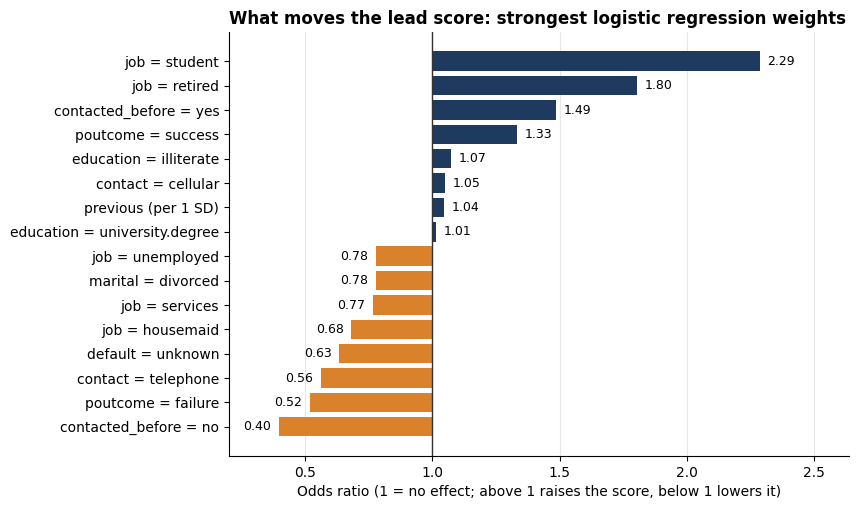

In [29]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(strongest.index, strongest.values - 1, left=1, color=[ORANGE if v < 1 else NAVY for v in strongest.values])
ax.axvline(1, color="#333333", linewidth=1)
for i, value in enumerate(strongest.values):
    ax.text(value + (0.03 if value > 1 else -0.03), i, f"{value:.2f}", va="center",
            ha="left" if value > 1 else "right", fontsize=9)
ax.set_xlim(0.2, strongest.max() + 0.35)
ax.set_xlabel("Odds ratio (1 = no effect; above 1 raises the score, below 1 lowers it)")
ax.set_title("What moves the lead score: strongest logistic regression weights")
ax.grid(axis="y", visible=False)
fig.savefig(IMG_DIR / "10_score_drivers_odds_ratios.png")
plt.show()

### Permutation importance on the test period

Odds ratios describe what the model learned from the training period. Permutation importance asks a different
question: **which columns does the ranking of the *later* calls actually depend on?** Each column in turn is
shuffled (which destroys its information) and the drop in ROC AUC on the test set is recorded. A large drop
means the model relied on that column; a drop near zero means it did not.

In [30]:
importance = permutation_importance(final_model, test[WHO], test["subscribed"],
                                    scoring="roc_auc", n_repeats=10, random_state=SEED)

importance_table = pd.DataFrame({"auc_drop": importance.importances_mean, "std": importance.importances_std},
                                index=WHO).sort_values("auc_drop", ascending=False)
importance_table.round(4)

,auc_drop,std
contacted_before,0.0551,0.0038
job,0.0232,0.0019
poutcome,0.0224,0.0027
contact,0.0132,0.0023
campaign,0.0086,0.0014
default,0.0061,0.0016
previous,0.0054,0.0017
education,0.0038,0.0009
loan,-0.0000,0.0002
age,-0.0002,0.0000


**Reading the result.**

- **Odds ratios.** Clients who were never contacted before have lower odds (0.40), as do previous failures (0.52) and landline
  contacts (0.56). The strongest upward weights are for students (2.29), retired clients (1.80) and previous contact
  (1.49). Combined, a previous subscriber has 5.9 times the odds of a never-contacted client, other things equal, and mobile
  contacts have 1.87 times the odds of landline contacts. These are weights inside one model, not causal effects, and
  job groups with few clients have uncertain weights.
- **Permutation importance.** On the later calls the ranking depends most on `contacted_before` (AUC drop 0.055),
  then `job` (0.023), `poutcome` (0.022) and `contact` (0.013). Age, housing loan, personal loan and marital status
  have a drop of about zero: shuffling them changes nothing, so they contribute little to the ranking on future calls.
- This agrees with notebook 01: previous-campaign history and contact channel matter, the rest matters little.

## 12. Summary

**Question.** Who should the call centre phone first, and how much better is that than calling at random?

**Answer.** On later calls the model never saw (May 2009 to Nov 2010, 8,236 calls, 30.8% conversion):

| Measure | Result |
|---|---|
| Subscribers reached by calling the top 10% of the scored list | 22.8% (lift 2.28) |
| Subscribers reached by calling the top 20% | 39.5% (lift 1.97, random would reach 20%) |
| Subscribers reached by calling the top 50% | 68.8% (lift 1.38) |
| Simple rule (previous subscribers first), top 20% | 37.4% |
| ROC AUC of the lead score | 0.70 |
| Conversion in the top-scored decile / bottom decile | 70.1% / 13.9% |

**Main points**

1. **No leakage.** `duration` is excluded. Including it would make the model look far better (AUC 0.95, lift 4.4) for
   a reason that cannot exist in practice.
2. **Time-ordered testing.** A random split overstates performance, especially with the economic indicators, which are
   dropped for that reason.
3. **Most of the lift comes from previous-campaign history.** A one-line rule gets most of the way; the model adds a
   modest improvement, mostly lower in the list.
4. **Performance depends on the period.** Rolling time-based tests show the AUC near 0.5 in the early, low-conversion
   weeks. The scores rank clients but are not calibrated probabilities (14.1% predicted against 30.8% actual).
5. **The profit scenario uses assumed costs and values**; its only purpose is to show the method.

**Limits.** One Portuguese bank, 2008 to 2010, during a financial crisis; observational data; the year is
reconstructed from row order. Before any real use, re-train and re-test on current data with the bank's own costs.